# **Week 5: Healthcare Data Understanding, Cleaning & Exploratory Analysis**


**Input:** Original healthcare dataset

**Output:** healthcare_preprocessed.csv (used for Week 6)

**1. Problem Statement**
Healthcare datasets contain patient demographic details, medical conditions, admission information, test results and billing records. Missing values, inconsistent date formats and non-standard categorical values can affect the accuracy of healthcare analysis.

This project focuses on cleaning and exploring healthcare records to understand patient demographics, admission patterns, medical conditions, billing amounts and length of hospital stay.

**2. Objectives**
1. Clean missing and inconsistent values in healthcare records.
2. Standardize medical conditions, test results and admission types.
3. Analyze patient age and gender distributions.
4. Calculate billing and hospital-stay statistics.
5. Segment patients based on medical conditions.
6. Prepare a clean dataset for Week 6 visualization and analysis.

Step 1: Import libraries and load data

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")

df = pd.read_csv("/content/drive/MyDrive/EDA-Skill/healthcare_dataset.csv")

df.head()

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
0,Bobby JacksOn,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal
1,LesLie TErRy,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive
2,DaNnY sMitH,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal
3,andrEw waTtS,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal
4,adrIENNE bEll,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458,Urgent,2022-10-09,Penicillin,Abnormal


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Step 2: Data understanding

In [5]:
print("Dataset Shape:", df.shape)

print("\nColumns:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include='all'))

Dataset Shape: (55500, 15)

Columns:
Index(['Name', 'Age', 'Gender', 'Blood Type', 'Medical Condition',
       'Date of Admission', 'Doctor', 'Hospital', 'Insurance Provider',
       'Billing Amount', 'Room Number', 'Admission Type', 'Discharge Date',
       'Medication', 'Test Results'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55500 entries, 0 to 55499
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Name                55500 non-null  object 
 1   Age                 55500 non-null  int64  
 2   Gender              55500 non-null  object 
 3   Blood Type          55500 non-null  object 
 4   Medical Condition   55500 non-null  object 
 5   Date of Admission   55500 non-null  object 
 6   Doctor              55500 non-null  object 
 7   Hospital            55500 non-null  object 
 8   Insurance Provider  55500 non-null  object 
 9   Billing Amoun

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
count,55500,55500.000000,55500,55500,55500,55500,55500,55500,55500,55500.000000,55500.000000,55500,55500,55500,55500
unique,49992,NaN,2,8,6,1827,40341,39876,5,NaN,NaN,3,1856,5,3
top,DAvId muNoZ,NaN,Male,A-,Arthritis,2024-03-16,Michael Smith,LLC Smith,Cigna,NaN,NaN,Elective,2020-03-15,Lipitor,Abnormal
freq,3,NaN,27774,6969,9308,50,27,44,11249,NaN,NaN,18655,53,11140,18627
mean,NaN,51.539459,NaN,NaN,NaN,NaN,NaN,NaN,NaN,25539.316097,301.134829,NaN,NaN,NaN,NaN
std,NaN,19.602454,NaN,NaN,NaN,NaN,NaN,NaN,NaN,14211.454431,115.243069,NaN,NaN,NaN,NaN
min,NaN,13.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-2008.492140,101.000000,NaN,NaN,NaN,NaN
25%,NaN,35.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13241.224652,202.000000,NaN,NaN,NaN,NaN
50%,NaN,52.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,25538.069376,302.000000,NaN,NaN,NaN,NaN
75%,NaN,68.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,37820.508436,401.000000,NaN,NaN,NaN,NaN


Step 3: Standardize column names

In [6]:
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(' ', '_')
)

print(df.columns.tolist())

['name', 'age', 'gender', 'blood_type', 'medical_condition', 'date_of_admission', 'doctor', 'hospital', 'insurance_provider', 'billing_amount', 'room_number', 'admission_type', 'discharge_date', 'medication', 'test_results']


Step 4: Check missing values

In [7]:
missing_report = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (
        df.isnull().sum() / len(df)
    ) * 100
})

display(missing_report)

,Missing_Count,Missing_Percentage
name,0,0.0
age,0,0.0
gender,0,0.0
blood_type,0,0.0
medical_condition,0,0.0
date_of_admission,0,0.0
doctor,0,0.0
hospital,0,0.0
insurance_provider,0,0.0
billing_amount,0,0.0


Step 5: Check duplicate records

In [8]:
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 534


In [9]:
df = df.drop_duplicates()

print("Dataset Shape After Removing Duplicates:", df.shape)

Dataset Shape After Removing Duplicates: (54966, 15)


Step 6: Clean categorical columns

In [10]:
categorical_columns = [
    'name',
    'gender',
    'blood_type',
    'medical_condition',
    'doctor',
    'hospital',
    'insurance_provider'
]

for col in categorical_columns:
    df[col] = df[col].astype('string').str.strip()

print("Categorical columns cleaned.")

Categorical columns cleaned.


Step 7: Convert numerical and date columns

In [11]:
df['age'] = pd.to_numeric(df['age'], errors='coerce')

df['billing_amount'] = pd.to_numeric(
    df['billing_amount'],
    errors='coerce'
)

df['date_of_admission'] = pd.to_datetime(
    df['date_of_admission'],
    errors='coerce'
)

df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 54966 entries, 0 to 55499
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   name                54966 non-null  string        
 1   age                 54966 non-null  int64         
 2   gender              54966 non-null  string        
 3   blood_type          54966 non-null  string        
 4   medical_condition   54966 non-null  string        
 5   date_of_admission   54966 non-null  datetime64[ns]
 6   doctor              54966 non-null  string        
 7   hospital            54966 non-null  string        
 8   insurance_provider  54966 non-null  string        
 9   billing_amount      54966 non-null  float64       
 10  room_number         54966 non-null  int64         
 11  admission_type      54966 non-null  object        
 12  discharge_date      54966 non-null  object        
 13  medication          54966 non-null  object        


Step 8: Handle missing values

In [12]:
print(df.isnull().sum())

name                  0
age                   0
gender                0
blood_type            0
medical_condition     0
date_of_admission     0
doctor                0
hospital              0
insurance_provider    0
billing_amount        0
room_number           0
admission_type        0
discharge_date        0
medication            0
test_results          0
dtype: int64


In [13]:
df['age'] = df['age'].fillna(df['age'].median())

df['billing_amount'] = df['billing_amount'].fillna(
    df['billing_amount'].median()
)

for col in categorical_columns:
    df[col] = df[col].fillna('Unknown')

print("Missing values after handling:")
print(df.isnull().sum())

Missing values after handling:
name                  0
age                   0
gender                0
blood_type            0
medical_condition     0
date_of_admission     0
doctor                0
hospital              0
insurance_provider    0
billing_amount        0
room_number           0
admission_type        0
discharge_date        0
medication            0
test_results          0
dtype: int64


Step 9: Validate age and billing values

In [14]:
print("Invalid Age Records:")
display(df[(df['age'] < 0) | (df['age'] > 120)])

print("Negative Billing Records:")
display(df[df['billing_amount'] < 0])

Invalid Age Records:


,name,age,gender,blood_type,medical_condition,date_of_admission,doctor,hospital,insurance_provider,billing_amount,room_number,admission_type,discharge_date,medication,test_results


Negative Billing Records:


,name,age,gender,blood_type,medical_condition,date_of_admission,doctor,hospital,insurance_provider,billing_amount,room_number,admission_type,discharge_date,medication,test_results
132,ashLEy ERIcKSoN,32,Female,AB-,Cancer,2019-11-05,Gerald Hooper,"and Johnson Moore, Branch",Aetna,-502.507813,376,Urgent,2019-11-23,Penicillin,Normal
799,CHRisTOPHer wEiss,49,Female,AB-,Asthma,2023-02-16,Kelly Thompson,Hunter-Hughes,Aetna,-1018.245371,204,Elective,2023-03-09,Penicillin,Inconclusive
1018,AsHley WaRnER,60,Male,A+,Hypertension,2021-12-21,Andrea Bentley,"and Wagner, Lee Klein",Aetna,-306.364925,426,Elective,2022-01-11,Ibuprofen,Normal
1421,JAY galloWaY,74,Female,O+,Asthma,2021-01-20,Debra Everett,Group Peters,Blue Cross,-109.097122,381,Emergency,2021-02-09,Ibuprofen,Abnormal
2103,josHUa wilLIamSon,72,Female,B-,Diabetes,2021-03-21,Wendy Ramos,"and Huff Reeves, Dennis",Blue Cross,-576.727907,369,Urgent,2021-04-17,Aspirin,Abnormal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
52213,mr. ChRIStOPhER aLvARaDO,74,Male,AB+,Obesity,2022-06-03,Mr. Dean Guzman DDS,Johnson Inc,Blue Cross,-1310.272895,257,Elective,2022-06-13,Paracetamol,Inconclusive
52629,gABrieLlE deCkER,66,Male,AB-,Arthritis,2022-11-07,William Krause,Diaz-Bishop,Cigna,-676.852502,354,Urgent,2022-11-30,Penicillin,Normal
53204,AsHley WaRnER,55,Male,A+,Hypertension,2021-12-21,Andrea Bentley,"and Wagner, Lee Klein",Aetna,-306.364925,426,Elective,2022-01-11,Ibuprofen,Normal
53232,dAnIel dRaKe,68,Female,B+,Hypertension,2020-04-24,Brett Ray,Carr Ltd,Aetna,-591.917419,426,Elective,2020-04-26,Lipitor,Abnormal


Step 10: Create age groups

In [15]:
df['age_group'] = pd.cut(
    df['age'],
    bins=[0, 18, 35, 59, 120],
    labels=['0-18', '19-35', '36-59', '60+'],
    include_lowest=True
)

display(df['age_group'].value_counts().sort_index())

,count
age_group,
0-18,886
19-35,13519
36-59,19613
60+,20948


Step 11: Analyze gender distribution

,count
gender,
Male,27496
Female,27470


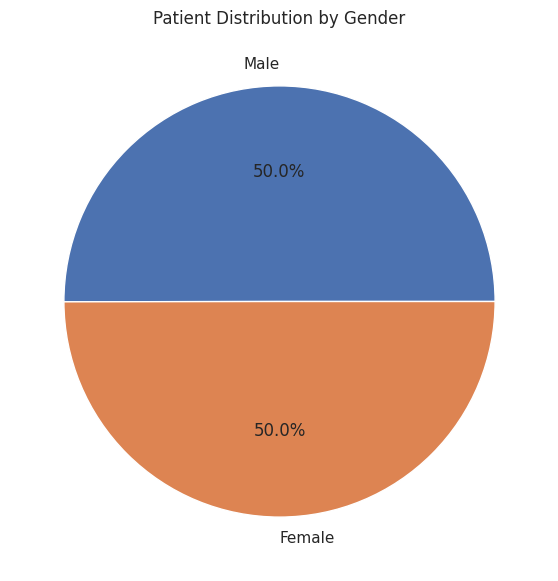

In [16]:
gender_counts = df['gender'].value_counts()

display(gender_counts)

gender_counts.plot(
    kind='pie',
    autopct='%1.1f%%',
    figsize=(7, 7)
)

plt.title('Patient Distribution by Gender')
plt.ylabel('')
plt.show()

Step 12: Analyze blood type distribution

,count
blood_type,
A-,6898
A+,6896
B+,6885
AB+,6882
AB-,6874
B-,6872
O+,6855
O-,6804


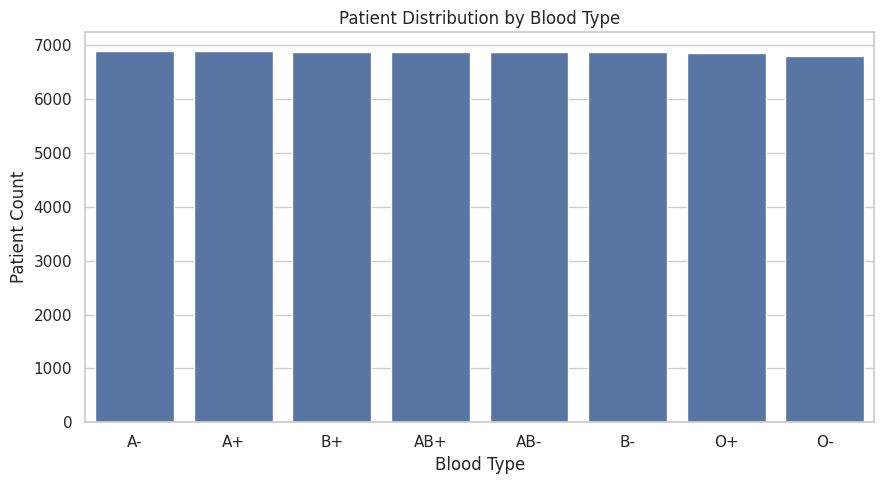

In [17]:
blood_counts = df['blood_type'].value_counts()

display(blood_counts)

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='blood_type',
    order=blood_counts.index
)

plt.title('Patient Distribution by Blood Type')
plt.xlabel('Blood Type')
plt.ylabel('Patient Count')

plt.tight_layout()
plt.show()

Step 13: Analyze medical conditions

,count
medical_condition,
Arthritis,9218
Diabetes,9216
Hypertension,9151
Obesity,9146
Cancer,9140
Asthma,9095


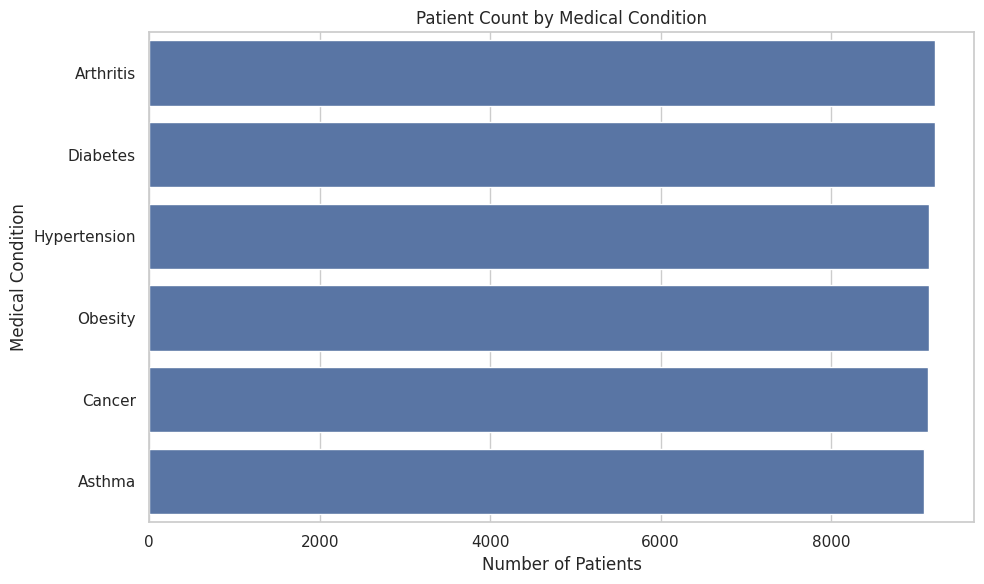

In [18]:
condition_counts = df['medical_condition'].value_counts()

display(condition_counts)

plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    y='medical_condition',
    order=condition_counts.index
)

plt.title('Patient Count by Medical Condition')
plt.xlabel('Number of Patients')
plt.ylabel('Medical Condition')

plt.tight_layout()
plt.show()

Step 14: Analyze admission dates

In [19]:
df['admission_year'] = df['date_of_admission'].dt.year

year_counts = df['admission_year'].value_counts().sort_index()

display(year_counts)

,count
admission_year,
2019,7300
2020,11172
2021,10816
2022,10915
2023,10936
2024,3827


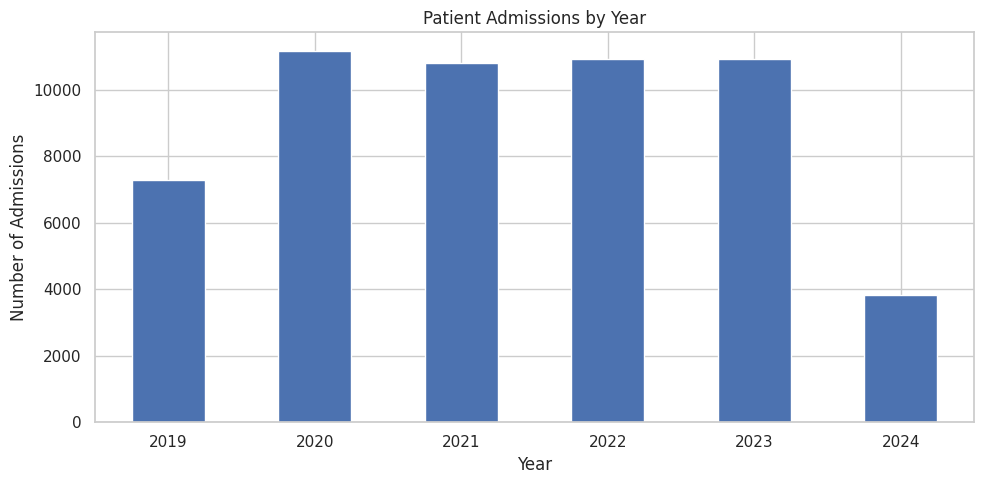

In [20]:
year_counts.plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Patient Admissions by Year')
plt.xlabel('Year')
plt.ylabel('Number of Admissions')

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Step 15: Analyze insurance providers

,count
insurance_provider,
Cigna,11139
Medicare,11039
UnitedHealthcare,11014
Blue Cross,10952
Aetna,10822


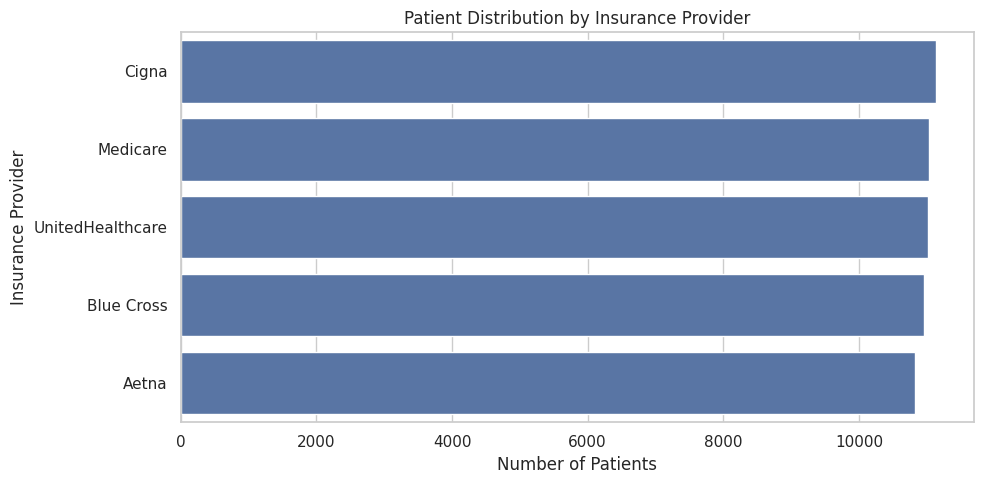

In [21]:
insurance_counts = df['insurance_provider'].value_counts()

display(insurance_counts)

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    y='insurance_provider',
    order=insurance_counts.index
)

plt.title('Patient Distribution by Insurance Provider')
plt.xlabel('Number of Patients')
plt.ylabel('Insurance Provider')

plt.tight_layout()
plt.show()

Step 16: Analyze billing amount

In [22]:
print(df['billing_amount'].describe())

count    54966.000000
mean     25544.306284
std      14208.409711
min      -2008.492140
25%      13243.718641
50%      25542.749145
75%      37819.858159
max      52764.276736
Name: billing_amount, dtype: float64


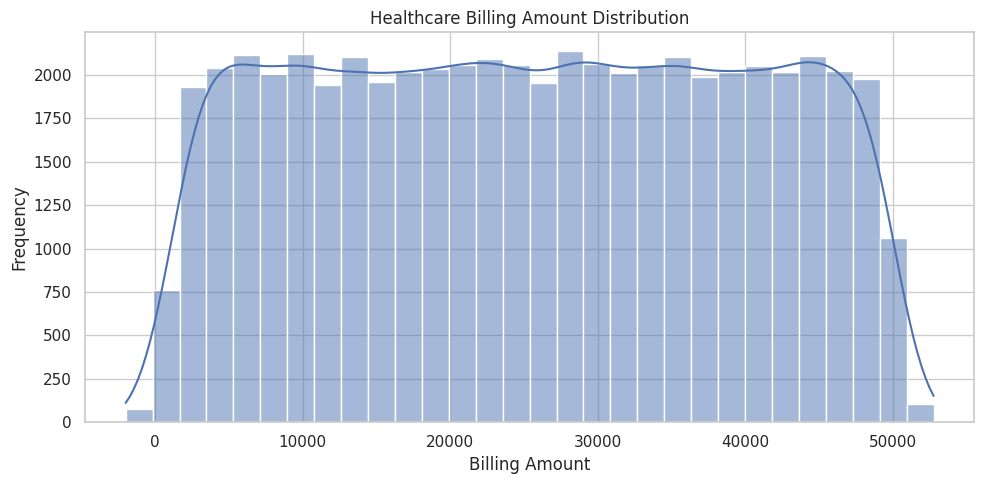

In [23]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df['billing_amount'].dropna(),
    bins=30,
    kde=True
)

plt.title('Healthcare Billing Amount Distribution')
plt.xlabel('Billing Amount')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

Step 17: Compare billing by medical condition

In [24]:
condition_billing = df.groupby(
    'medical_condition'
)['billing_amount'].agg(
    ['count', 'mean', 'median', 'sum']
)

display(condition_billing)

,count,mean,median,sum
medical_condition,,,,
Arthritis,9218,25511.783246,25599.182892,2.351676e+08
Asthma,9095,25633.461696,25628.413135,2.331363e+08
Cancer,9140,25152.322947,24910.709821,2.298922e+08
Diabetes,9216,25660.478635,25647.705432,2.364870e+08
Hypertension,9151,25503.058720,25281.630443,2.333785e+08
Obesity,9146,25804.361902,26145.578798,2.360067e+08


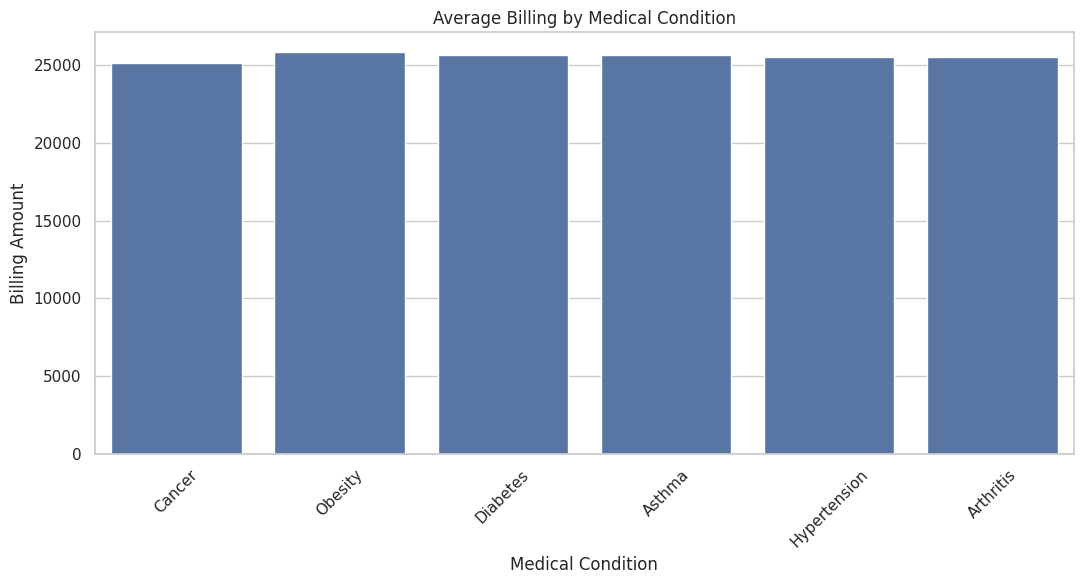

In [25]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=df,
    x='medical_condition',
    y='billing_amount',
    errorbar=None
)

plt.title('Average Billing by Medical Condition')
plt.xlabel('Medical Condition')
plt.ylabel('Billing Amount')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Step 18: Compare billing by insurance provider

In [26]:
insurance_billing = df.groupby(
    'insurance_provider'
)['billing_amount'].agg(
    ['count', 'mean', 'median', 'sum']
)

display(insurance_billing)

,count,mean,median,sum
insurance_provider,,,,
Aetna,10822,25549.689648,25765.376030,2.764987e+08
Blue Cross,10952,25603.460603,25580.538127,2.804091e+08
Cigna,11139,25525.998670,25537.181217,2.843341e+08
Medicare,11039,25628.320208,25629.326758,2.829110e+08
UnitedHealthcare,11014,25414.506208,25222.108878,2.799154e+08


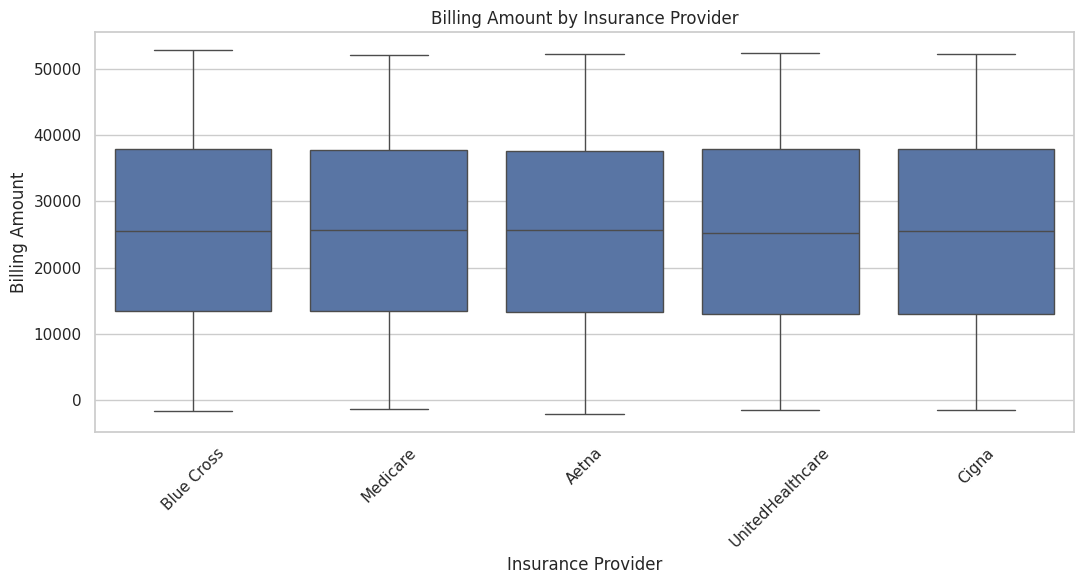

In [27]:
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df,
    x='insurance_provider',
    y='billing_amount'
)

plt.title('Billing Amount by Insurance Provider')
plt.xlabel('Insurance Provider')
plt.ylabel('Billing Amount')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Step 19: Create healthcare summary

In [28]:
healthcare_summary = pd.DataFrame({
    'Metric': [
        'Total Patient Records',
        'Average Age',
        'Average Billing Amount',
        'Median Billing Amount',
        'Minimum Billing Amount',
        'Maximum Billing Amount',
        'Total Medical Conditions',
        'Total Insurance Providers'
    ],

    'Value': [
        len(df),
        df['age'].mean(),
        df['billing_amount'].mean(),
        df['billing_amount'].median(),
        df['billing_amount'].min(),
        df['billing_amount'].max(),
        df['medical_condition'].nunique(),
        df['insurance_provider'].nunique()
    ]
})

display(healthcare_summary)

,Metric,Value
0,Total Patient Records,54966.000000
1,Average Age,51.535185
2,Average Billing Amount,25544.306284
3,Median Billing Amount,25542.749145
4,Minimum Billing Amount,-2008.492140
5,Maximum Billing Amount,52764.276736
6,Total Medical Conditions,6.000000
7,Total Insurance Providers,5.000000


Step 20: Export cleaned dataset and reports

In [29]:
df.to_csv(
    'healthcare_preprocessed.csv',
    index=False
)

healthcare_summary.to_csv(
    'healthcare_summary.csv',
    index=False
)

condition_billing.to_csv(
    'condition_billing_summary.csv'
)

insurance_billing.to_csv(
    'insurance_billing_summary.csv'
)

print("Week 5 reports exported successfully.")

Week 5 reports exported successfully.
